In [1]:
import sys, os
sys.path.insert(0, r"C:\Users\taran\sample_project\project_root")

In [2]:
import numpy as np


In [3]:
class Node:
    def __init__(self, name, state):
        """
        name: str
        state: dict of parameters
        """
        self.name = name
        self.state = state
        self.input_signal = 0.0
        self.output_signal = 0.0

    def forward(self, signal):
        """
        Default forward pass (can be overridden later)
        """
        self.input_signal = signal
        self.output_signal = signal
        return self.output_signal


In [4]:
class Edge:
    def __init__(self, src, dst, attenuation=1.0, noise=0.0):
        self.src = src
        self.dst = dst
        self.attenuation = attenuation
        self.noise = noise

    def transmit(self):
        signal = self.src.output_signal
        noise_term = np.random.normal(0, self.noise)
        transmitted = signal * self.attenuation + noise_term
        return transmitted


In [5]:
# Cortex
cortex = Node(
    name="Cortex",
    state={
        "drive_intensity": 1.0,
        "noise_level": 0.0
    }
)

# Upper Motor Neuron
umn = Node(
    name="UMN",
    state={
        "health": 1.0,
        "signal_gain": 1.0
    }
)

# Lower Motor Neuron
lmn = Node(
    name="LMN",
    state={
        "health": 1.0,
        "signal_gain": 1.0
    }
)

# Neuromuscular Junction
nmj = Node(
    name="NMJ",
    state={
        "transmission_efficiency": 1.0
    }
)

# Muscle
muscle = Node(
    name="Muscle",
    state={
        "activation_level": 0.0,
        "max_force": 1.0
    }
)


In [6]:
def cortex_forward(node):
    output = node.state["drive_intensity"]
    node.output_signal = output
    return output

def neuron_forward(node, signal):
    output = signal * node.state["health"] * node.state["signal_gain"]
    node.output_signal = output
    return output

def nmj_forward(node, signal):
    output = signal * node.state["transmission_efficiency"]
    node.output_signal = output
    return output

def muscle_forward(node, signal):
    activation = np.clip(signal, 0, 1)
    force = activation * node.state["max_force"]
    node.state["activation_level"] = activation
    node.output_signal = force
    return force


In [7]:
edges = [
    Edge(cortex, umn, attenuation=1.0),
    Edge(umn, lmn, attenuation=1.0),
    Edge(lmn, nmj, attenuation=1.0),
    Edge(nmj, muscle, attenuation=1.0)
]


In [8]:
# Cortex generates signal
signal = cortex_forward(cortex)
print(f"Cortex output: {signal:.3f}")

# UMN
signal = neuron_forward(umn, edges[0].transmit())
print(f"UMN output: {signal:.3f}")

# LMN
signal = neuron_forward(lmn, edges[1].transmit())
print(f"LMN output: {signal:.3f}")

# NMJ
signal = nmj_forward(nmj, edges[2].transmit())
print(f"NMJ output: {signal:.3f}")

# Muscle
force = muscle_forward(muscle, edges[3].transmit())
print(f"Muscle force output: {force:.3f}")


Cortex output: 1.000
UMN output: 1.000
LMN output: 1.000
NMJ output: 1.000
Muscle force output: 1.000


In [9]:
lmn.state["health"] = 0.4


In [10]:
# Upper Motor Neuron
umn.state.update({
    "degeneration_burden": 0.0,   # 0 = healthy, 1 = dead
})

# Lower Motor Neuron
lmn.state.update({
    "degeneration_burden": 0.0,
    "excitotoxicity_factor": 0.0  # secondary damage amplifier
})


In [11]:
def neuron_forward(node, signal):
    effective_health = np.clip(
        node.state["health"] * (1.0 - node.state["degeneration_burden"]),
        0.0,
        1.0
    )
    
    output = signal * effective_health * node.state["signal_gain"]
    node.output_signal = output
    return output


In [12]:
def lmn_forward(node, signal):
    stress_threshold = 0.8
    stress = max(0.0, signal - stress_threshold)
    
    excitotoxic_penalty = stress * node.state["excitotoxicity_factor"]
    
    effective_health = np.clip(
        node.state["health"] * (1.0 - node.state["degeneration_burden"] - excitotoxic_penalty),
        0.0,
        1.0
    )
    
    output = signal * effective_health * node.state["signal_gain"]
    node.output_signal = output
    return output


In [13]:
def lmn_forward(node, signal):
    stress_threshold = 0.8
    stress = max(0.0, signal - stress_threshold)
    
    excitotoxic_penalty = stress * node.state["excitotoxicity_factor"]
    
    effective_health = np.clip(
        node.state["health"] * (1.0 - node.state["degeneration_burden"] - excitotoxic_penalty),
        0.0,
        1.0
    )
    
    output = signal * effective_health * node.state["signal_gain"]
    node.output_signal = output
    return output


In [14]:
# Cortex
signal = cortex_forward(cortex)
print(f"Cortex output: {signal:.3f}")

# UMN
signal = neuron_forward(umn, edges[0].transmit())
print(f"UMN output: {signal:.3f}")

# LMN (new logic)
signal = lmn_forward(lmn, edges[1].transmit())
print(f"LMN output: {signal:.3f}")

# NMJ
signal = nmj_forward(nmj, edges[2].transmit())
print(f"NMJ output: {signal:.3f}")

# Muscle
force = muscle_forward(muscle, edges[3].transmit())
print(f"Muscle force output: {force:.3f}")


Cortex output: 1.000
UMN output: 1.000
LMN output: 0.400
NMJ output: 0.400
Muscle force output: 0.400


In [15]:
umn.state["degeneration_burden"] = 0.5


In [16]:
lmn.state["degeneration_burden"] = 0.3
lmn.state["excitotoxicity_factor"] = 0.5


In [17]:
umn.state["degeneration_burden"] = 0.0
lmn.state["degeneration_burden"] = 0.7


In [18]:
from mnd_model.physiology.motor_unit import build_motor_unit
from mnd_model.dynamics.simulator import simulate

print("Imports OK")


Imports OK


In [19]:
cortex, umn, lmn, nmj, muscle, edges = build_motor_unit()

umn.state["degeneration_rate"] = 0.004      # slower, upstream
lmn.state["degeneration_rate"] = 0.01       # faster, downstream
lmn.state["excitotoxicity_factor"] = 0.6    # stress-sensitive


In [20]:
history = simulate(
    cortex,
    umn,
    lmn,
    nmj,
    muscle,
    edges,
    timesteps=250,
    dt=1.0
)


In [21]:
history["force"][:10], history["force"][-10:]


([np.float64(0.88),
  np.float64(0.8211024000000001),
  np.float64(0.7977054515199999),
  np.float64(0.7869800972800001),
  np.float64(0.7763155430400001),
  np.float64(0.7657117888),
  np.float64(0.7551688345600001),
  np.float64(0.74468668032),
  np.float64(0.73426532608),
  np.float64(0.72390477184)],
 [np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0)])

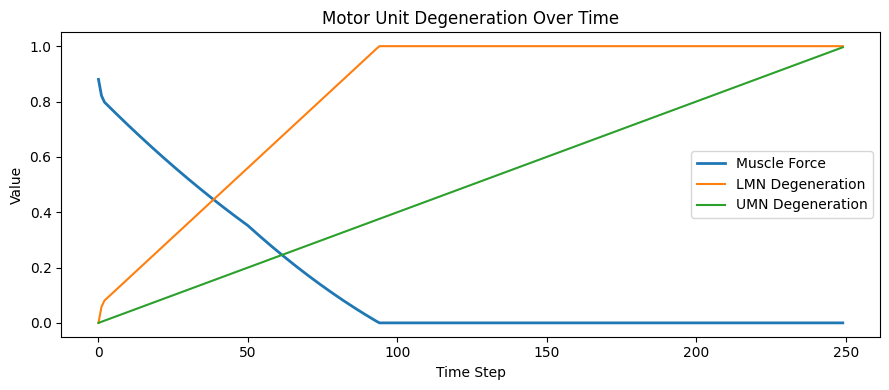

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,4))
plt.plot(history["force"], label="Muscle Force", linewidth=2)
plt.plot(history["lmn_degeneration"], label="LMN Degeneration")
plt.plot(history["umn_degeneration"], label="UMN Degeneration")

plt.xlabel("Time Step")
plt.ylabel("Value")
plt.title("Motor Unit Degeneration Over Time")
plt.legend()
plt.tight_layout()
plt.show()


In [23]:
umn.state["degeneration_rate"] = 0.01
lmn.state["degeneration_rate"] = 0.0


In [24]:
umn.state["degeneration_rate"] = 0.0
lmn.state["degeneration_rate"] = 0.015


In [25]:
lmn.state["excitotoxicity_factor"] = 0.0


In [26]:
from mnd_model.cohorts.phenotypes import (
    FAST_PROGRESSOR,
    SLOW_PROGRESSOR,
    UMN_DOMINANT,
    LMN_DOMINANT
)
from mnd_model.cohorts.run_cohort import run_patient

patients = [
    FAST_PROGRESSOR,
    SLOW_PROGRESSOR,
    UMN_DOMINANT,
    LMN_DOMINANT
]

results = {}
for p in patients:
    results[p.label] = run_patient(p)


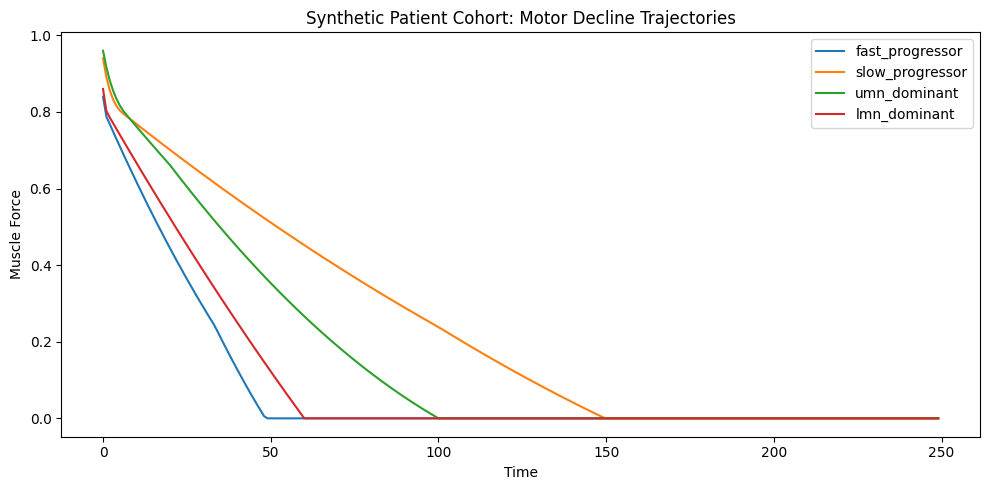

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

for label, history in results.items():
    plt.plot(history["force"], label=label)

plt.xlabel("Time")
plt.ylabel("Muscle Force")
plt.title("Synthetic Patient Cohort: Motor Decline Trajectories")
plt.legend()
plt.tight_layout()
plt.show()



In [28]:
import numpy as np

def time_to_failure(force, threshold=0.2):
    for i, f in enumerate(force):
        if f < threshold:
            return i
    return np.inf

for label, history in results.items():
    ttf = time_to_failure(history["force"])
    print(label, "time_to_failure:", ttf)


fast_progressor time_to_failure: 36
slow_progressor time_to_failure: 108
umn_dominant time_to_failure: 69
lmn_dominant time_to_failure: 44


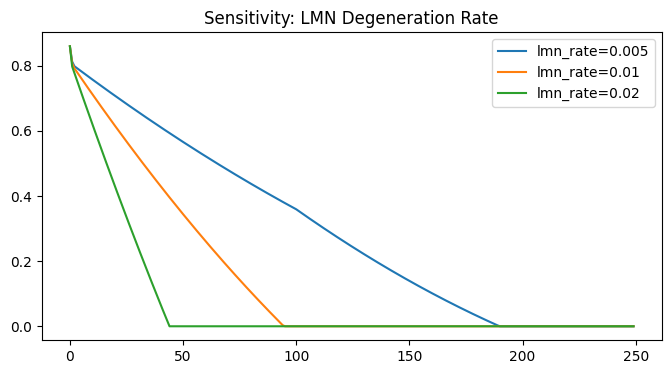

In [29]:
from copy import deepcopy
import matplotlib.pyplot as plt

base = LMN_DOMINANT

rates = [0.005, 0.01, 0.02]
plt.figure(figsize=(8,4))

for r in rates:
    p = deepcopy(base)
    p.lmn_degeneration_rate = r
    hist = run_patient(p)
    plt.plot(hist["force"], label=f"lmn_rate={r}")

plt.legend()
plt.title("Sensitivity: LMN Degeneration Rate")
plt.show()


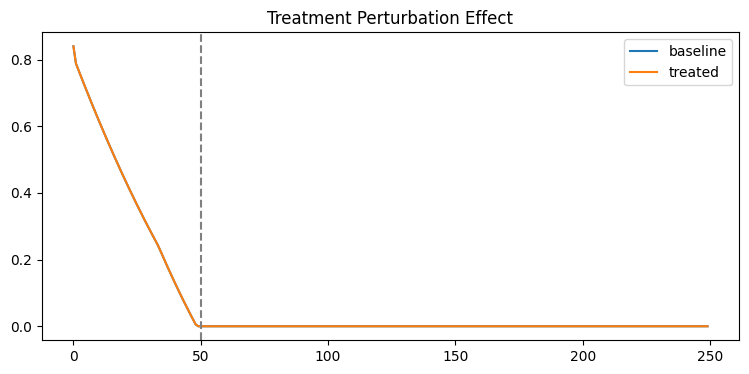

In [33]:
from mnd_model.treatments.library import NEUROPROTECTIVE
from mnd_model.cohorts.instantiate import instantiate_patient

baseline = run_patient(FAST_PROGRESSOR)
treated = simulate(
    *instantiate_patient(FAST_PROGRESSOR),
    timesteps=250,
    treatment=NEUROPROTECTIVE
)

plt.figure(figsize=(9,4))
plt.plot(baseline["force"], label="baseline")
plt.plot(treated["force"], label="treated")
plt.axvline(NEUROPROTECTIVE.start_time, linestyle="--", color="gray")
plt.legend()
plt.title("Treatment Perturbation Effect")
plt.show()


In [37]:
%pip install torch torchvision torchaudio


Note: you may need to restart the kernel to use updated packages.


In [38]:
import torch
import torch.nn as nn

print(torch.__version__)
print(nn.Linear(4, 2))


2.9.1+cpu
Linear(in_features=4, out_features=2, bias=True)


In [39]:
import sys
print(sys.executable)


C:\Users\taran\miniconda3\python.exe


In [40]:
from mnd_model.cohorts.phenotypes import FAST_PROGRESSOR
from mnd_model.cohorts.instantiate import instantiate_patient
from mnd_model.dynamics.simulator import simulate
from mnd_model.treatments.library import NEUROPROTECTIVE


In [41]:
baseline = simulate(
    *instantiate_patient(FAST_PROGRESSOR),
    timesteps=250,
    treatment=None
)


In [42]:
import copy

treatment_times = {
    "early": 20,
    "mid": 60,
    "late": 120
}

treated_results = {}

for label, t_start in treatment_times.items():
    tx = copy.deepcopy(NEUROPROTECTIVE)
    tx.start_time = t_start

    treated_results[label] = simulate(
        *instantiate_patient(FAST_PROGRESSOR),
        timesteps=250,
        treatment=tx
    )



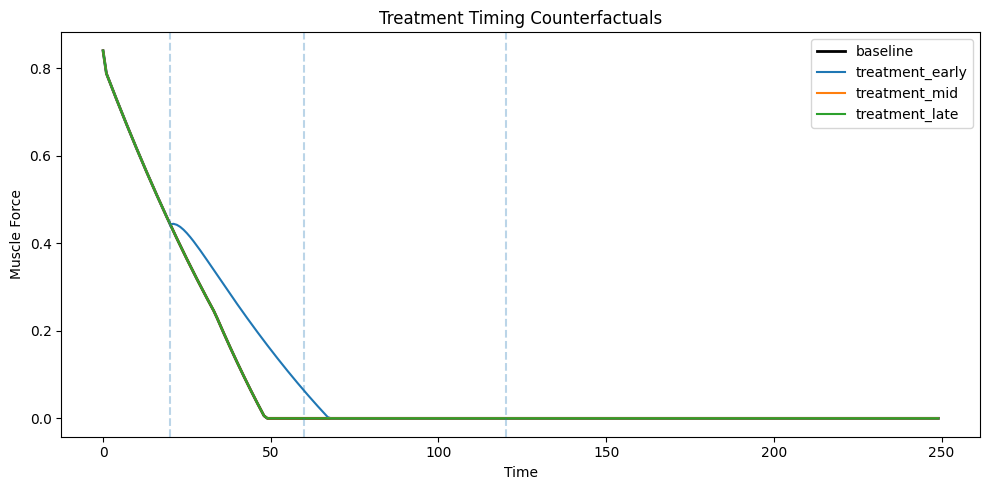

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(baseline["force"], label="baseline", linewidth=2, color="black")

for label, hist in treated_results.items():
    plt.plot(hist["force"], label=f"treatment_{label}")

for t in treatment_times.values():
    plt.axvline(t, linestyle="--", alpha=0.3)

plt.xlabel("Time")
plt.ylabel("Muscle Force")
plt.title("Treatment Timing Counterfactuals")
plt.legend()
plt.tight_layout()
plt.show()


In [44]:
def time_to_failure(force, threshold=0.2):
    for i, f in enumerate(force):
        if f < threshold:
            return i
    return None


In [45]:
print("Baseline:", time_to_failure(baseline["force"]))
for label, hist in treated_results.items():
    print(label, time_to_failure(hist["force"]))


Baseline: 36
early 46
mid 36
late 36


In [46]:
import numpy as np

def auc(force):
    return np.trapz(force)

print("Baseline AUC:", auc(baseline["force"]))
for label, hist in treated_results.items():
    print(label, auc(hist["force"]))


Baseline AUC: 18.687196799999988
early 23.15775587747318
mid 18.687196799999988
late 18.687196799999988


C:\Users\taran\AppData\Local\Temp\ipykernel_22684\412418902.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(force)


In [47]:
tx_late = copy.deepcopy(NEUROPROTECTIVE)
tx_late.start_time = 200

too_late = simulate(
    *instantiate_patient(FAST_PROGRESSOR),
    timesteps=250,
    treatment=tx_late
)


In [49]:
from copy import deepcopy
from mnd_model.cohorts.phenotypes import FAST_PROGRESSOR
from mnd_model.cohorts.instantiate import instantiate_patient
from mnd_model.dynamics.simulator import simulate
from mnd_model.treatments.treatments import Treatment


In [50]:
baseline = simulate(
    *instantiate_patient(FAST_PROGRESSOR),
    timesteps=250,
    treatment=None
)


In [51]:
# Mechanism A — Neuroprotection (global slowing)
NEUROPROTECTIVE = Treatment(
    umn_rate_multiplier=0.7,
    lmn_rate_multiplier=0.7,
    excitotoxicity_multiplier=1.0,
    start_time=40,
    label="neuroprotective"
)


In [52]:
# Mechanism B — Excitotoxicity Suppression (LMN-specific)
EXCITO_BLOCK = Treatment(
    umn_rate_multiplier=1.0,
    lmn_rate_multiplier=1.0,
    excitotoxicity_multiplier=0.3,
    start_time=40,
    label="excitotoxic_block"
)


In [53]:
# Mechanism C — LMN-Selective Protection
LMN_TARGETED = Treatment(
    umn_rate_multiplier=1.0,
    lmn_rate_multiplier=0.5,
    excitotoxicity_multiplier=1.0,
    start_time=40,
    label="lmn_targeted"
)


In [54]:
# Run Counterfactuals
mechanisms = {
    "neuroprotective": NEUROPROTECTIVE,
    "excitotoxic_block": EXCITO_BLOCK,
    "lmn_targeted": LMN_TARGETED
}

results = {}

for label, tx in mechanisms.items():
    results[label] = simulate(
        *instantiate_patient(FAST_PROGRESSOR),
        timesteps=250,
        treatment=deepcopy(tx)
    )


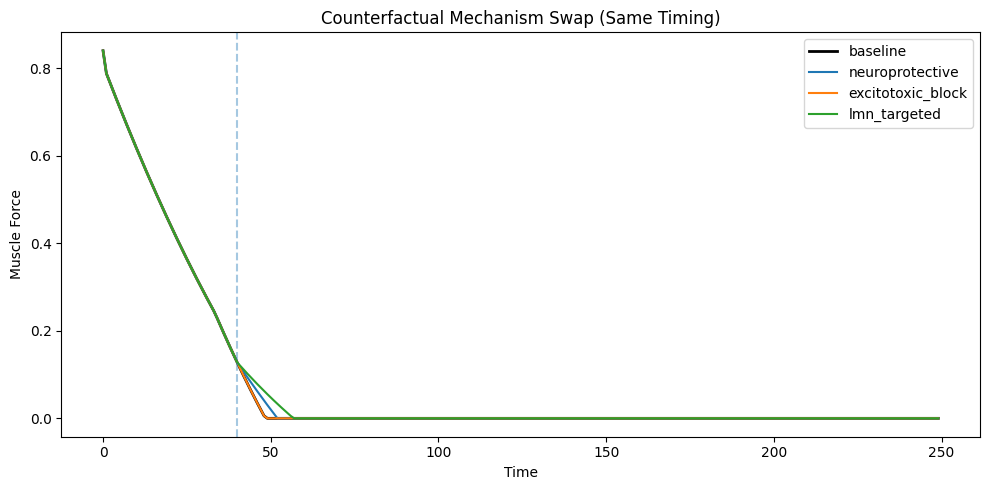

In [55]:
# Compare Force Trajectories
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(baseline["force"], label="baseline", color="black", linewidth=2)

for label, hist in results.items():
    plt.plot(hist["force"], label=label)

plt.axvline(40, linestyle="--", alpha=0.4)
plt.xlabel("Time")
plt.ylabel("Muscle Force")
plt.title("Counterfactual Mechanism Swap (Same Timing)")
plt.legend()
plt.tight_layout()
plt.show()


In [56]:
# Quantify Differences 
def time_to_failure(force, threshold=0.2):
    for i, f in enumerate(force):
        if f < threshold:
            return i
    return None


In [57]:
print("Baseline:", time_to_failure(baseline["force"]))
for label, hist in results.items():
    print(label, time_to_failure(hist["force"]))


Baseline: 36
neuroprotective 36
excitotoxic_block 36
lmn_targeted 36


In [58]:
import numpy as np

def auc(force):
    return np.trapz(force)

print("Baseline AUC:", auc(baseline["force"]))
for label, hist in results.items():
    print(label, auc(hist["force"]))


Baseline AUC: 18.687196799999988
neuroprotective 18.910187999999987
excitotoxic_block 18.687196799999988
lmn_targeted 19.186716799999985


C:\Users\taran\AppData\Local\Temp\ipykernel_22684\44028998.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(force)
